# XGBoost and LSTM comparison

The reusable runner fits the models in a separate Python process so a native model library failure cannot terminate this notebook kernel. It compares the majority baseline, direction persistence baseline, Logistic Regression, XGBoost and LSTM across five expanding date folds on identical timestamps. Each LSTM observation uses 12 consecutive five minute bars within one session, and scaling is fitted on training rows only.

In [1]:
# Locate the saved results and the separate runner used only when outputs are missing.
from pathlib import Path
import subprocess
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
cwd = Path.cwd()
project_root = cwd.parent if cwd.name == 'notebooks' else cwd
runner = project_root / 'python_code' / 'run_advanced_models.py'
results_dir = project_root / 'results'
metrics_file = results_dir / 'advanced_model_fold_metrics.csv'
predictions_file = results_dir / 'advanced_model_predictions.csv'

In [2]:
# Use saved results when present; keep model fitting outside this notebook kernel.
if metrics_file.exists() and predictions_file.exists():
    print('Using the saved model run. To recompute, run python_code/run_advanced_models.py from the project root.')
else:
    run = subprocess.run(
        [sys.executable, str(runner)],
        cwd=project_root,
        capture_output=True,
        text=True,
        check=False,
    )
    print(run.stdout)
    if run.returncode != 0:
        print(run.stderr)
        raise RuntimeError(f'Model runner exited with status {run.returncode}; notebook kernel remains separate.')

Using the saved model run. To recompute, run python_code/run_advanced_models.py from the project root.


In [3]:
# Review fold means, spread and pooled predictions from the common test rows.
fold_metrics = pd.read_csv(metrics_file)
predictions = pd.read_csv(predictions_file, parse_dates=['datetime', 'signal_datetime', 'next_datetime', 'entry_datetime', 'exit_datetime'])
display(fold_metrics.groupby(['ETF', 'model'])[['accuracy', 'balanced_accuracy', 'f1_up', 'roc_auc']].agg(['mean', 'std']).round(4))

prediction_columns = {
    'Majority baseline': 'baseline_prediction',
    'Direction persistence baseline': 'persistence_prediction',
    'Logistic regression': 'logistic_prediction',
    'XGBoost': 'xgboost_prediction',
    'LSTM': 'lstm_prediction',
}
pooled_rows = []
for ticker, ticker_predictions in predictions.groupby('ETF'):
    for model_name, column in prediction_columns.items():
        pooled_rows.append({
            'ETF': ticker,
            'model': model_name,
            'common_test_rows': len(ticker_predictions),
            'accuracy': (ticker_predictions['actual'] == ticker_predictions[column]).mean(),
            'up_label_rate': (ticker_predictions['actual'] == 1).mean(),
        })
display(pd.DataFrame(pooled_rows).set_index(['ETF', 'model']).round(4))

accuracy         balanced_accuracy          \
                                       mean     std              mean     std   
ETF model                                                                       
QQQ Direction persistence baseline   0.4813  0.0141            0.4813  0.0141   
    LSTM                             0.5142  0.0069            0.5118  0.0081   
    Logistic regression              0.5075  0.0073            0.5042  0.0088   
    Majority baseline                0.5055  0.0034            0.5000  0.0000   
    XGBoost                          0.5153  0.0104            0.5138  0.0111   
SPY Direction persistence baseline   0.4789  0.0098            0.4788  0.0098   
    LSTM                             0.5132  0.0133            0.5121  0.0138   
    Logistic regression              0.5130  0.0087            0.5113  0.0084   
    Majority baseline                0.5042  0.0086            0.5000  0.0000   
    XGBoost                          0.5175  0.0114            0.5163  0.0117   

                                     f1_up         roc_auc          
                                      mean     std    mean     std  
ETF model                                                           
QQQ Direction persistence baseline  0.4840  0.0164     NaN     NaN  
    LSTM                            0.5999  0.0112  0.5192  0.0190  
    Logistic regression             0.6220  0.0182  0.5135  0.0219  
    Majority baseline               0.6716  0.0030     NaN     NaN  
    XGBoost                         0.5743  0.0179  0.5230  0.0124  
SPY Direction persistence baseline  0.4802  0.0138     NaN     NaN  
    LSTM                            0.5994  0.0228  0.5258  0.0163  
    Logistic regression             0.5884  0.0139  0.5195  0.0124  
    Majority baseline               0.6703  0.0076     NaN     NaN  
    XGBoost                         0.5783  0.0181  0.5283  0.0201

common_test_rows  accuracy  up_label_rate
ETF model                                                                    
QQQ Majority baseline                          23419    0.5055         0.5055
    Direction persistence baseline             23419    0.4813         0.5055
    Logistic regression                        23419    0.5075         0.5055
    XGBoost                                    23419    0.5154         0.5055
    LSTM                                       23419    0.5142         0.5055
SPY Majority baseline                          23532    0.5041         0.5041
    Direction persistence baseline             23532    0.4789         0.5041
    Logistic regression                        23532    0.5130         0.5041
    XGBoost                                    23532    0.5174         0.5041
    LSTM                                       23532    0.5131         0.5041

## Mean fold scores and variation

The axes are zoomed around 50% to make small differences readable. The table above gives the exact values; error bars show one standard deviation across the five folds. Baselines do not have probability scores, so ROC AUC is shown only for models that output probabilities.

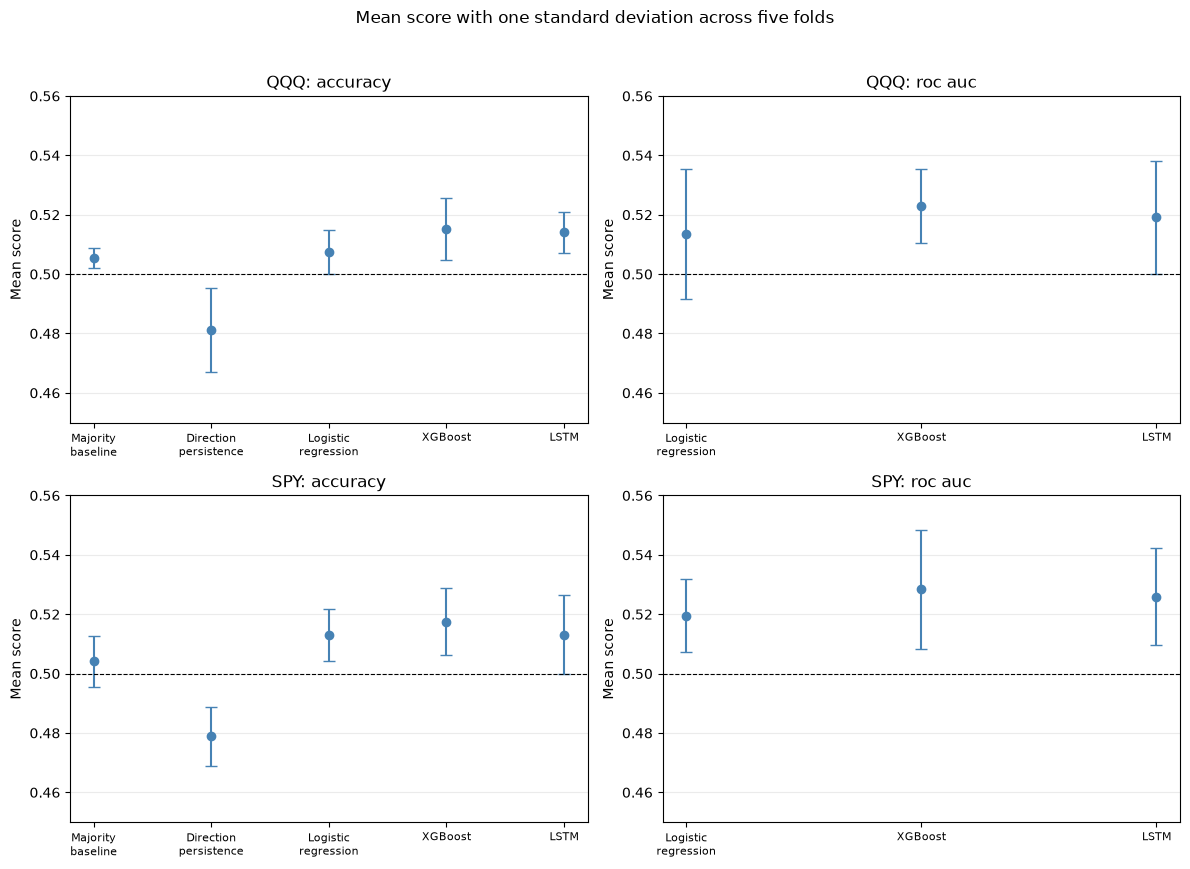

In [4]:
# Compare fold means and variation without squeezing long model names.
model_order = ['Majority baseline', 'Direction persistence baseline', 'Logistic regression', 'XGBoost', 'LSTM']
short_names = {
    'Majority baseline': 'Majority\nbaseline',
    'Direction persistence baseline': 'Direction\npersistence',
    'Logistic regression': 'Logistic\nregression',
    'XGBoost': 'XGBoost',
    'LSTM': 'LSTM',
}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, ticker in enumerate(['QQQ', 'SPY']):
    ticker_metrics = fold_metrics.loc[fold_metrics['ETF'].eq(ticker)]
    for col, metric in enumerate(['accuracy', 'roc_auc']):
        axis = axes[row, col]
        grouped = ticker_metrics.groupby('model')[metric].agg(['mean', 'std']).reindex(model_order).dropna()
        positions = range(len(grouped))
        axis.errorbar(
            positions, grouped['mean'], yerr=grouped['std'],
            fmt='o', capsize=4, color='steelblue',
        )
        axis.axhline(0.5, color='black', linestyle='--', linewidth=0.8)
        labels = [short_names[name] for name in grouped.index]
        axis.set_xticks(list(positions), labels, fontsize=8)
        axis.set_ylim(0.45, 0.56)
        axis.set_title(f'{ticker}: {metric.replace("_", " ")}')
        axis.set_ylabel('Mean score')
        axis.grid(axis='y', alpha=0.25)
fig.suptitle('Mean score with one standard deviation across five folds')
fig.tight_layout(rect=(0, 0.02, 1, 0.96))
plt.show()


## Evaluation boundary

These are next bar open to close direction results using fixed initial settings, not a completed hyperparameter search. Transaction costs and trading performance belong to a separate evaluation stage. Results are written to `results/advanced_model_fold_metrics.csv` and `results/advanced_model_predictions.csv`.